In [52]:
# Load tools

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import statsmodels.api as sm
from arch import arch_model
from fredapi import Fred
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from arch.unitroot import PhillipsPerron

In [5]:
# Pull 2 year yield data, transform dataframe to end of month values and to basis points

fred = Fred(api_key=os.environ["FRED_API_KEY"]  # free key: https://fred.stlouisfed.org/docs/api/api_key.html)
two_year_note = fred.get_series('DGS2',observation_start='2000-01-01')
df_level = two_year_note.to_frame(name='2 year rate')
df_level = df_level.groupby(df_level.index.to_period("M")).last()
df_level = df_level.iloc[:-1] # drop the current, unfinished monthly value
df_level.index = df_level.index.to_timestamp()
df = (100*df_level.diff()).dropna() # compute change in yields, transform from percentages to basis points, drop 1st value

In [6]:
# Split into estimation and test samples

df_is  = df.loc[:"2019-12-01"]    # estimation ("in-sample"): 239 months
df_oos = df.loc["2020-01-01":]    # test ("out-of-sample"):    82 months

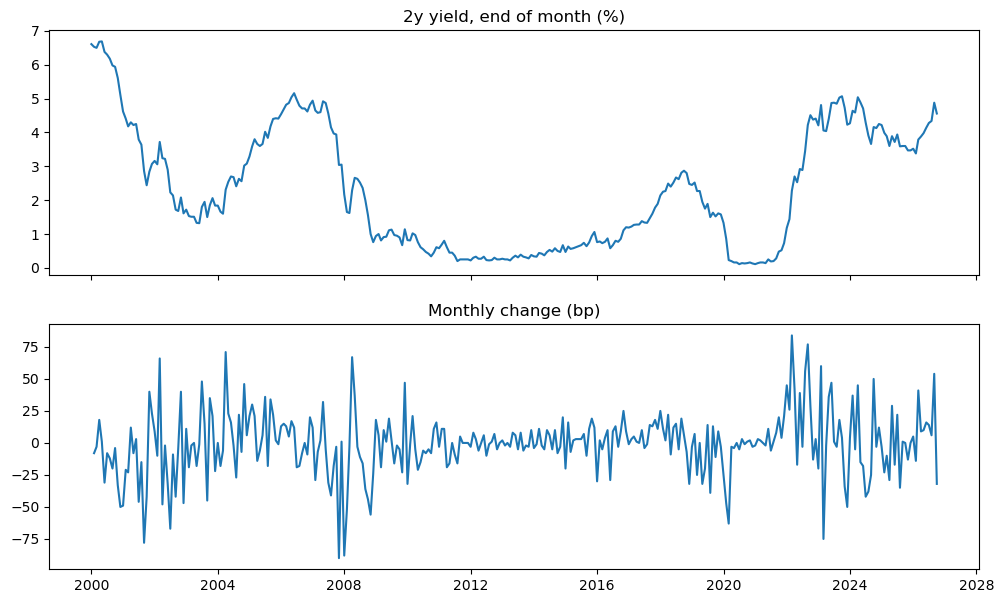

       2 year rate
count   239.000000
mean     -2.104603
std      22.685129
min     -90.000000
25%     -10.000000
50%      -1.000000
75%      10.500000
max      71.000000


In [7]:
# Plot the data

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(df_level); ax[0].set_title("2y yield, end of month (%)")
ax[1].plot(df); ax[1].set_title("Monthly change (bp)")
plt.show()

print(df_is.describe())

In [8]:
# Check stationarity

def unit_root_tests(series, name):
    adf_p  = adfuller(series, regression="c", autolag="AIC")[1] # H0: unit root. Rejection = stationary
    kpss_p = kpss(series, regression="c", nlags="auto")[1] # H0: no unit root. Rejection = non-stationary
    # 2 stationarity tests used as unit-root tests have low power with very persistent series
    print(f"{name:8s}  ADF p = {adf_p:.3f} (H0: unit root)   KPSS p = {kpss_p:.3f} (H0: stationary)")

unit_root_tests(df_level.loc[:"2019-12-01"], "Level")
unit_root_tests(df_is, "Change")

Level     ADF p = 0.078 (H0: unit root)   KPSS p = 0.010 (H0: stationary)
Change    ADF p = 0.000 (H0: unit root)   KPSS p = 0.100 (H0: stationary)


<ipython>:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c", nlags="auto")[1] # H0: no unit root. Rejection = non-stationary
<ipython>:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(series, regression="c", nlags="auto")[1] # H0: no unit root. Rejection = non-stationary


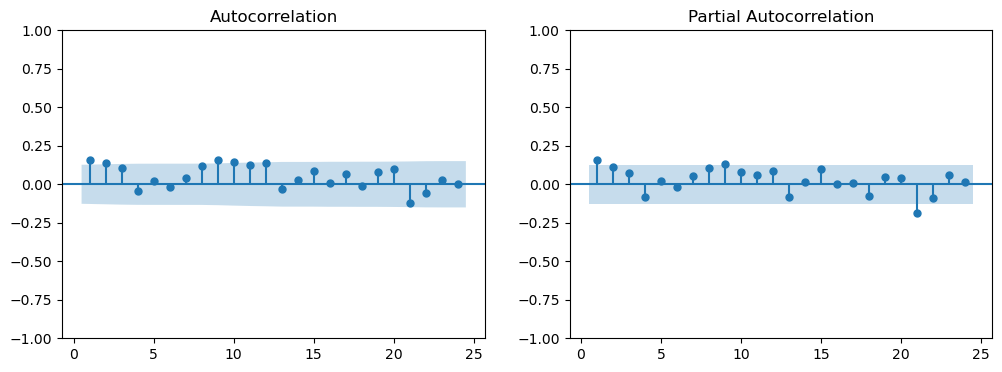

In [9]:
# Look at stationarity patterns over time

# ACF: the correlation between this month’s change and the change k months ago
# PACF: the correlation with the change k months ago after removing the effect of the months in between.
# AR(p): PACF that cuts off after lag p, while the ACF decays gradually.
# MA(p): ACF that cuts off after lag q.

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(df_is,  lags=24, ax=ax[0], zero=False)
plot_pacf(df_is, lags=24, ax=ax[1], zero=False, method="ywm")
plt.show()

# Conclusion: Lag 1 outside band in both, oag 2 outside band in ACF only. Possibly short AR model but possibly none

In [10]:
# Choose number of lags with information criteria
# AIC: tends to pick bigger models and is aimed at forecasting. BIC: tends to pick smaller models and is aimed at finding the “true” model

y_common = df_is.iloc[12:]          # same sample for every candidate, so the scores are comparable

ic = {}
for p in range(13):
    res = ARIMA(y_common, order=(p, 0, 0), trend="c").fit() # no differencing, no MA terms, include constant c
    ic[p] = {"AIC": res.aic, "BIC": res.bic}
ic = pd.DataFrame(ic).T
print(ic.round(1))
print("BIC picks p =", ic["BIC"].idxmin(), "  AIC picks p =", ic["AIC"].idxmin())

# Conclusion: differences between lags small, evidence for any lag weak. BIC picks 0, AIC picks 2. Test p = 0, 1 and 2

       AIC     BIC
0   2062.2  2069.1
1   2060.8  2071.0
2   2060.5  2074.2
3   2061.6  2078.7
4   2061.7  2082.3
5   2063.7  2087.7
6   2065.1  2092.5
7   2066.7  2097.6
8   2067.3  2101.5
9   2065.9  2103.6
10  2066.1  2107.2
11  2066.0  2110.5
12  2065.1  2113.1
BIC picks p = 0   AIC picks p = 2


In [11]:
# Estimate model

ar0 = ARIMA(df_is, order=(0, 0, 0), trend="c").fit()
ar1 = ARIMA(df_is, order=(1, 0, 0), trend="c").fit()
ar2 = ARIMA(df_is, order=(2, 0, 0), trend="c").fit()
print(ar0.summary().tables[1])
print(ar1.summary().tables[1])
print(ar2.summary().tables[1])

# Conclusion: some evidence of momentum with AR(1) and AR(2)terms significant but doesn't explain much of variation 
# (sigma2 doesn't decrease much). Test residual diagnostics to see if constant variance assumption is met and se's accurate

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.1046      1.510     -1.394      0.163      -5.064       0.855
sigma2       512.4974     32.322     15.856      0.000     449.147     575.847
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.1067      1.771     -1.189      0.234      -5.578       1.365
ar.L1          0.1574      0.056      2.817      0.005       0.048       0.267
sigma2       499.6573     30.774     16.237      0.000     439.342     559.972
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.1055      2.095     -1.005      0.315      -6.212       2.001
ar.L1          0.1393      0.056      2.501      0.0

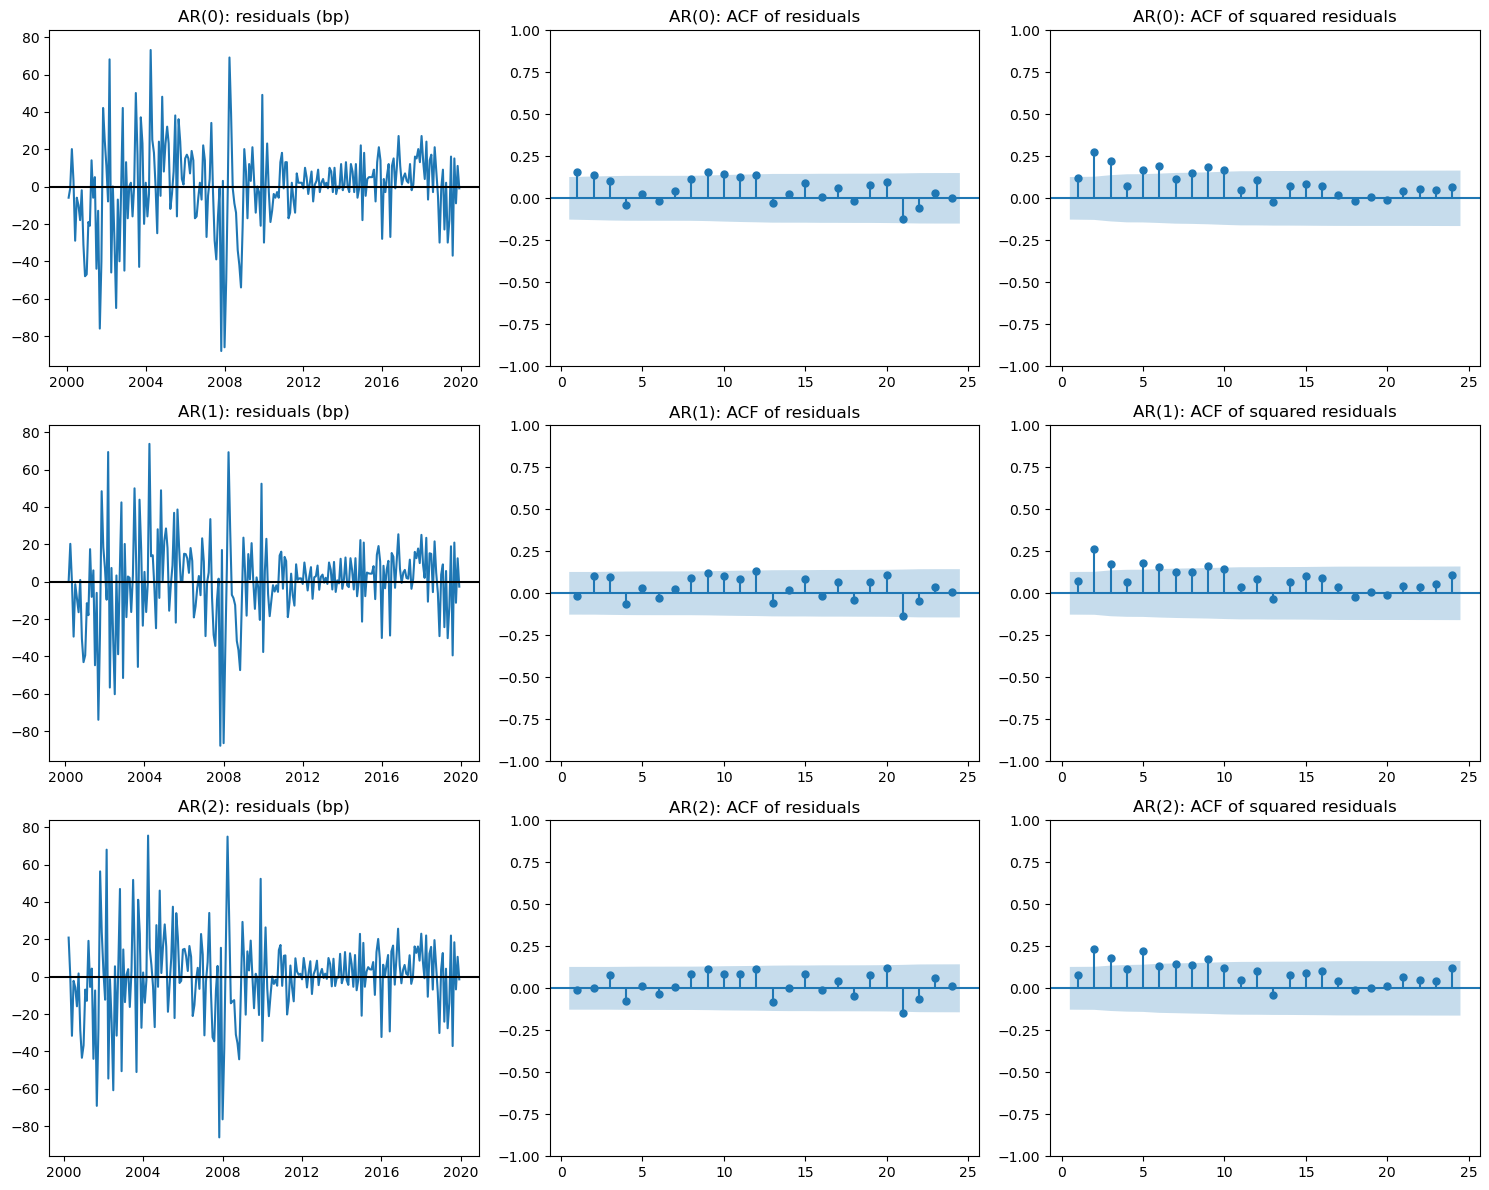

In [12]:
# Residual diagnostics - plot residuals and acf
# ACF of the residuals checks for leftover pattern in the level of the shocks: did the model miss some predictability?
# ACF of the squared residuals checks for pattern in their size: do big shocks follow big shocks? AC here means vol clustering

ar2 = ARIMA(df_is, order=(2, 0, 0), trend="c").fit()

models = {"AR(0)": (ar0,0),"AR(1)": (ar1, 1), "AR(2)": (ar2, 2)}   # name: (fitted model, number of lags)

fig, ax = plt.subplots(len(models), 3, figsize=(15, 4 * len(models)), sharey="col")
for row, (name, (fit, p)) in enumerate(models.items()):
    resid = fit.resid.iloc[p:]       # drop the first p residuals (lags not yet available)
    ax[row, 0].plot(resid); ax[row, 0].axhline(0, color="k")
    ax[row, 0].set_title(f"{name}: residuals (bp)")
    plot_acf(resid,      lags=24, ax=ax[row, 1], zero=False); ax[row, 1].set_title(f"{name}: ACF of residuals")
    plot_acf(resid ** 2, lags=24, ax=ax[row, 2], zero=False); ax[row, 2].set_title(f"{name}: ACF of squared residuals")
plt.tight_layout()
plt.show()

# Conclusion: ACF res shows AR(1) removes pattern in residuals, AR(2) not needed; ACF squared res show persistence ie vol clustering.
# Constant variance assumption not met

In [13]:
# Residual diagnostics – Ljung–Box test for autocorrelation
# H0: no autocorrelation up to lag m. Rejection (p < 0.05) = autocorrelation left in the residuals.
# model_df = number of AR lags fitted, so the degrees of freedom are m - p.

models = {"AR(0)": (ar0, 0), "AR(1)": (ar1, 1), "AR(2)": (ar2, 2)}

lb = {}
for name, (fit, p) in models.items():
    resid = fit.resid.iloc[p:]
    lb[name] = acorr_ljungbox(resid, lags=[6, 12, 24], model_df=p)["lb_pvalue"]

lb = pd.DataFrame(lb)
lb.index.name = "lag"
print("Ljung–Box p-values")
print(lb.round(4))

# Conclusion: evidence that AR(1) removes AC but also that variance clustering is causes test to over-reject at higher lags

Ljung–Box p-values
      AR(0)   AR(1)   AR(2)
lag                        
6    0.0309  0.2794  0.5163
12   0.0001  0.0315  0.1189
24   0.0009  0.0452  0.0617


In [14]:
# Residual diagnostics - ARCH-LM test for constant variance

lm_stat, lm_p, _, _ = het_arch(resid, nlags=12) # regress squared residuals on own lags. H0 = no ARCH effects. Rejection = vol clustering
print(f"ARCH-LM(12) p = {lm_p:.5f}")

# Conclusion: strong ARCH effects; ceofficient significance may be over-stated; Ljung-Box test over-rejects so AC may be illusion

ARCH-LM(12) p = 0.00240


AR(0): JB p = 3.33e-16, skew = -0.52, kurtosis = 5.47
AR(1): JB p = 0.00e+00, skew = -0.46, kurtosis = 5.64
AR(2): JB p = 8.78e-14, skew = -0.27, kurtosis = 5.41


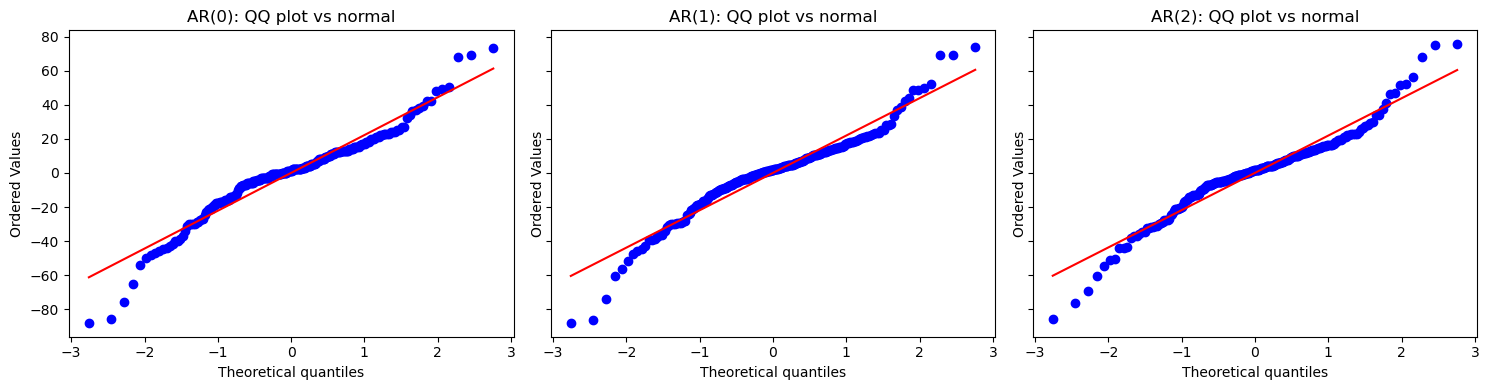

In [15]:
# Residual diagnostics - Normality
# Jarque-Bera: does skewness and volatility match normal distribution?
# Normality not needed for coefficients to be valid but impacts validity of forecast interval

# Residual diagnostics – normality (Jarque–Bera) and QQ plots
# H0: residuals are normal. Rejection (p < 0.05) = non-normal (skewed and/or fat-tailed).
# Normal benchmark: skew = 0, kurtosis = 3.

fig, ax = plt.subplots(1, len(models), figsize=(5 * len(models), 4), sharey=True)

for i, (name, (fit, p)) in enumerate(models.items()):
    r = fit.resid.iloc[p:]
    jb = stats.jarque_bera(r)
    print(f"{name}: JB p = {jb.pvalue:.2e}, skew = {stats.skew(r):.2f}, "
          f"kurtosis = {stats.kurtosis(r, fisher=False):.2f}")
    stats.probplot(r, dist="norm", plot=ax[i])
    ax[i].set_title(f"{name}: QQ plot vs normal")

plt.tight_layout()
plt.show()

# Conclusion: excess kurtosis means tails are clearly fatter than normal; skew means large falls more common than large rises

# Run AR(1)-GARCH model

https://arch.readthedocs.io/en/stable/univariate/univariate.html

In [16]:
# Fit GARCH model 
garch_model = arch_model(df_is, mean = "AR", lags = 1, vol = "GARCH", p = 1, q = 1, dist = "t", rescale = False,).fit(disp = 'off')

# Print GARCH model summary
print(garch_model.summary())

# Conclusion: AR(1) term no longer significant - momentum is result of misspecifying variance as constant when there is clustering
# Surpises in rates carry over to next month (alpha coefficient) and variance is sticky (beta)
# sign of regimes in volatility/vol shocks lasting a long time

                              AR - GARCH Model Results                              
Dep. Variable:                  2 year rate   R-squared:                      -0.001
Mean Model:                              AR   Adj. R-squared:                 -0.005
Vol Model:                            GARCH   Log-Likelihood:               -1030.67
Distribution:      Standardized Student's t   AIC:                           2073.35
Method:                  Maximum Likelihood   BIC:                           2094.18
                                              No. Observations:                  238
Date:                      Mon, Nov 09 2026   Df Residuals:                      236
Time:                              21:23:44   Df Model:                            2
                                 Mean Model                                
                    coef    std err          t      P>|t|  95.0% Conf. Int.
---------------------------------------------------------------------------
Const  

In [23]:
# Fit GARCH model with AR(0)

# Fit GARCH model 
garch_model = arch_model(df_is, mean = "AR", lags = 0, vol = "GARCH", p = 1, q = 1, dist = "t", rescale = False,).fit(disp = 'off',first_obs=1)

# Print GARCH model summary
print(garch_model.summary())

# Conclusion: AIC and BIC lower - use AR(0)-GARCH

                              AR - GARCH Model Results                              
Dep. Variable:                  2 year rate   R-squared:                       0.000
Mean Model:                              AR   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1030.84
Distribution:      Standardized Student's t   AIC:                           2071.68
Method:                  Maximum Likelihood   BIC:                           2089.05
                                              No. Observations:                  238
Date:                      Mon, Nov 09 2026   Df Residuals:                      237
Time:                              21:46:04   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
Const          0

In [53]:
# Test asymmetry with EGARCH/GJR-GARCH

# Fit GJR-GARCH model 
garch_model_gjr = arch_model(df_is, mean = "AR", lags = 0, vol = "GARCH", p = 1,o = 1, q = 1, dist = "t", rescale = False,).fit(disp = 'off',first_obs=1)

# Fit EGARCH model 
egarch_model = arch_model(df_is, mean = "AR", lags = 0, vol = "EGARCH", p = 1,o = 1, q = 1, dist = "t", rescale = False,).fit(disp = 'off',first_obs=1)

# Print model summaries
print(garch_model_gjr.summary())
print(egarch_model.summary())

# Conclusion: Info criteria worse than AR(0)-GARCH and asymmetry terms (gamma) insignificant - rate increases raise vol as much as decreases
# EGARCH avoids alpha + beta = 1 boundary problem - use AR(0)-EGARCH(1,1)
# EGARCH output: vol half life = ln(0.5)/ln(0.98) ≈ 34 months; rate surpises raise log variance next period; lr vol is ~ exp(ω/(2(1 − β))) ≈ 25bp/month

                            AR - GJR-GARCH Model Results                            
Dep. Variable:                  2 year rate   R-squared:                       0.000
Mean Model:                              AR   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -1030.84
Distribution:      Standardized Student's t   AIC:                           2073.67
Method:                  Maximum Likelihood   BIC:                           2094.51
                                              No. Observations:                  238
Date:                      Wed, Nov 11 2026   Df Residuals:                      237
Time:                              11:31:42   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
Const          0

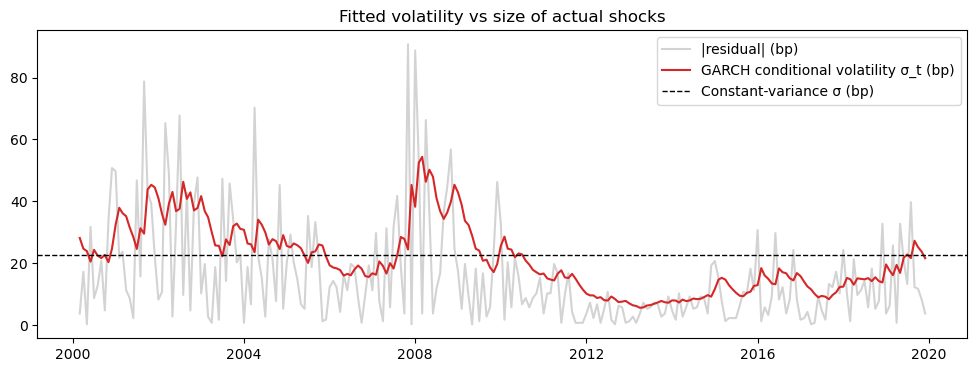

In [27]:
# Plot conditional volatility

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(egarch_model.resid.abs(), color="lightgrey", label="|residual| (bp)")
ax.plot(egarch_model.conditional_volatility, color="tab:red", label="GARCH conditional volatility σ_t (bp)")
ax.axhline(float(df_is.squeeze().std()), color="k", ls="--", lw=1, label="Constant-variance σ (bp)")
ax.set_title("Fitted volatility vs size of actual shocks"); ax.legend()
plt.show()

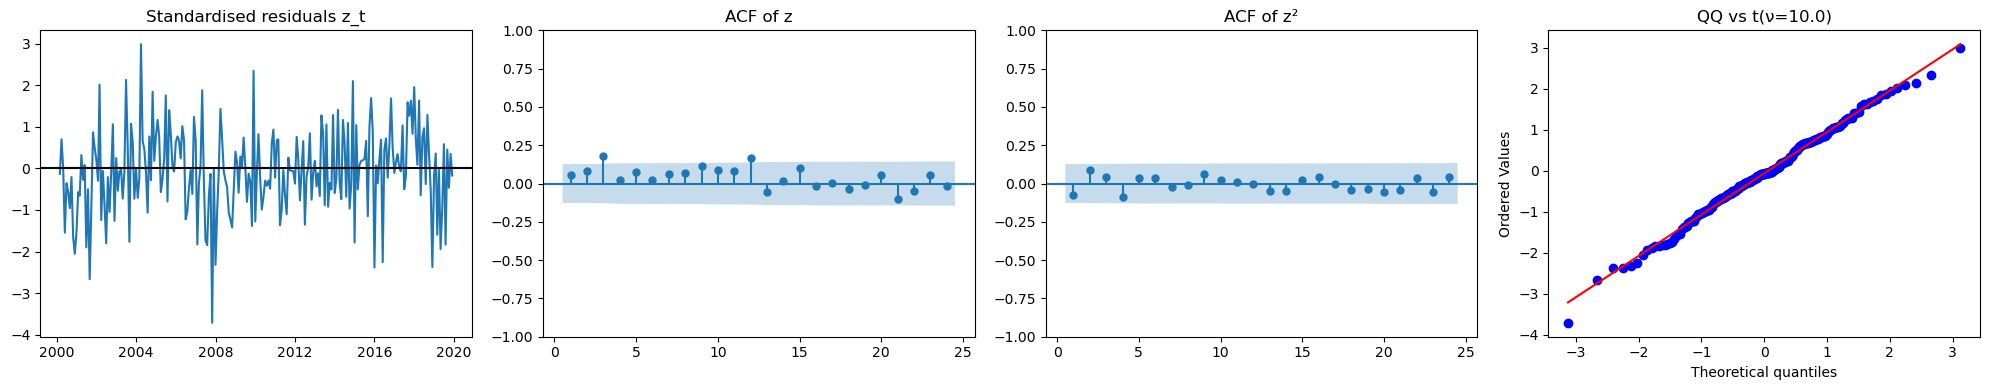

In [30]:
# Residual diagnostics - plot standardised residuals (standardisation removes time-varying vol so tests not distorted by vol clustering)

res = egarch_model                          # the model being checked
P = 0                                      # number of AR lags in its mean equation
z = (res.resid / res.conditional_volatility).dropna()
nu = res.params["nu"]
t_scale = np.sqrt((nu - 2) / nu)           # scale of a t(nu) with variance 1

# 6a. Plots
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].plot(z); ax[0].axhline(0, color="k"); ax[0].set_title("Standardised residuals z_t")
plot_acf(z,      lags=24, ax=ax[1], zero=False); ax[1].set_title("ACF of z")
plot_acf(z ** 2, lags=24, ax=ax[2], zero=False); ax[2].set_title("ACF of z²")
stats.probplot(z, dist=stats.t, sparams=(nu, 0, t_scale), plot=ax[3]); ax[3].set_title(f"QQ vs t(ν={nu:.1f})")
plt.tight_layout(); plt.show()

In [33]:
# test for AC of residuals post-GARCH (whether last month's surpise predicts direction of this month's)

print("Ljung–Box on z (dof adjusted for the AR lags):")
print(acorr_ljungbox(z, lags=[6, 12, 24], model_df=P))

# Conclusion: AC left in residuals, driven by lag 3 and 12. Likely due to monetary policy cycles

Ljung–Box on z (dof adjusted for the AR lags):
      lb_stat  lb_pvalue
6   11.711441   0.068725
12  27.559940   0.006413
24  36.582516   0.048138


In [34]:
# Test for ARCH effects - ie AC in squared residuals (whether big suprise last month predicts big surpise this month)

arch_test = het_arch(z)
arch_test_pvalue =  arch_test[1]
print("\nARCH Test Results:")
print(arch_test[1])
if arch_test_pvalue  < 0.05:
    print("Reject H0 and conclude that there is evidence of heteroskedasticity (ARCH effects) in the residuals.")
else:
    print("Don't reject H0 that there are no ARCH effects")


ARCH Test Results:
0.6261214323699698
Don't reject H0 that there are no ARCH effects


In [31]:
# test that t-distribution fits

ks = stats.kstest(z, "t", args=(nu, 0, t_scale))
print(f"\nKS test vs fitted t: p = {ks.pvalue:.3f}")
print(f"Sample kurtosis = {stats.kurtosis(z, fisher=False):.2f}   "
      f"implied by t(ν={nu:.1f}) = {3 + 6/(nu-4):.2f}   skew = {stats.skew(z):.2f}")

# Conclusion: don't reject H0 that t shape fits. Minor skew. Kurtosis consistent with t


KS test vs fitted t: p = 0.216
Sample kurtosis = 3.61   implied by t(ν=10.0) = 4.00   skew = -0.16


MEAN FORECASTS
  Random walk      RMSE = 29.2bp
  Historical mean  RMSE = 29.5bp   RMSE/RW = 1.008   OOS R² = -1.7%   CW p = 0.82
  AR(0)-EGARCH-t   RMSE = 29.1bp   RMSE/RW = 0.996   OOS R² = 0.7%   CW p = 0.16

VOLATILITY FORECASTS (scored against realised variance from daily data)
  Constant variance  QLIKE = 7.682   avg σ = 23.8bp
  AR(0)-EGARCH-t     QLIKE = 7.346   avg σ = 27.6bp
  DM p (EGARCH vs constant) = 0.051
  EGARCH 90% interval coverage = 82%


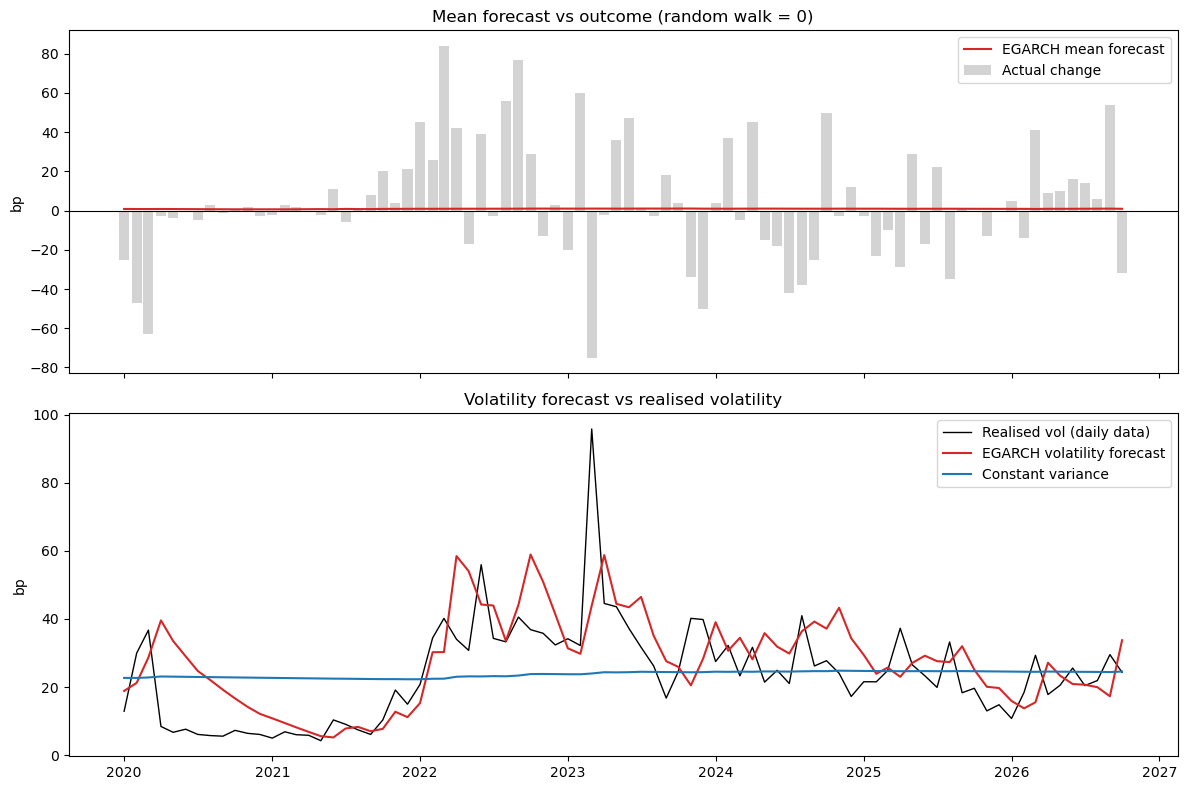

In [54]:
# Out-of-sample forecasts

df     = df.squeeze()
df_oos = df_oos.squeeze()
fc = pd.DataFrame(index=df_oos.index, columns=["mean", "var", "nu"], dtype=float)

for t in df_oos.index: # Expanding window forecasts: re-estimate each month
    origin = df.index[df.index.get_loc(t) - 1]                  # forecast is made the month before t
    res = arch_model(df.loc[:t], mean="Constant", vol="EGARCH", p=1, q=1,
                     dist="t", rescale=False).fit(disp="off", last_obs=t, show_warning=False)   # estimate up to t-1
    f = res.forecast(horizon=1, start=origin, reindex=False)
    fc.loc[t] = [f.mean.loc[origin].iloc[0], f.variance.loc[origin].iloc[0], res.params["nu"]]

# Benchmarks for mean and variance:
actual    = df_oos
rw_mean   = pd.Series(0.0, index=actual.index) # random walk: no change
hist_mean = df.expanding().mean().shift(1).loc[actual.index] # average of past changes
hist_var  = df.expanding().var().shift(1).loc[actual.index]  # constant variance: variance of past changes

# Realised variance from daily data: the "true" variance proxy for scoring volatility forecasts
dd = 100 * two_year_note.diff()
rv = (dd ** 2).groupby(dd.index.to_period("M")).sum()
rv.index = rv.index.to_timestamp()
rv = rv.loc[actual.index]

def hac_t(d):
    # t-stat for mean(d) = 0 with Newey–West standard errors
    d = np.asarray(d, dtype=float)
    r = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": int(len(d) ** (1 / 3))})
    return float(r.tvalues[0])

# Mean forecasts vs random walk
e_rw = actual - rw_mean
print("MEAN FORECASTS")
print(f"  Random walk      RMSE = {np.sqrt((e_rw**2).mean()):.1f}bp")
for name, f in [("Historical mean", hist_mean), ("AR(0)-EGARCH-t", fc["mean"])]:
    e = actual - f
    ratio = np.sqrt((e**2).mean() / (e_rw**2).mean())
    r2 = 1 - (e**2).sum() / (e_rw**2).sum()
    cw_p = 1 - stats.norm.cdf(hac_t(e_rw**2 - (e**2 - f**2)))     # Clark–West, one-sided
    print(f"  {name:16s} RMSE = {np.sqrt((e**2).mean()):.1f}bp   RMSE/RW = {ratio:.3f}   OOS R² = {r2:.1%}   CW p = {cw_p:.2f}")

# Volatility forecasts vs constant variance
qlike = lambda h: np.log(h) + rv / h                            # lower = better
dm_p = 2 * (1 - stats.norm.cdf(abs(hac_t(qlike(hist_var) - qlike(fc["var"])))))
q90 = stats.t.ppf(0.95, fc["nu"]) * np.sqrt((fc["nu"] - 2) / fc["nu"]) * np.sqrt(fc["var"])
coverage = ((actual - fc["mean"]).abs() <= q90).mean()

print("\nVOLATILITY FORECASTS (scored against realised variance from daily data)")
print(f"  Constant variance  QLIKE = {qlike(hist_var).mean():.3f}   avg σ = {np.sqrt(hist_var).mean():.1f}bp")
print(f"  AR(0)-EGARCH-t     QLIKE = {qlike(fc['var']).mean():.3f}   avg σ = {np.sqrt(fc['var']).mean():.1f}bp")
print(f"  DM p (EGARCH vs constant) = {dm_p:.3f}")
print(f"  EGARCH 90% interval coverage = {coverage:.0%}")

# ---- 5. Plot ----
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].bar(actual.index, actual.to_numpy(), width=25, color="lightgrey", label="Actual change")
ax[0].plot(fc.index, fc["mean"].to_numpy(), color="tab:red", label="EGARCH mean forecast")
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylabel("bp"); ax[0].legend()
ax[0].set_title("Mean forecast vs outcome (random walk = 0)")
ax[1].plot(rv.index, np.sqrt(rv).to_numpy(), color="k", lw=1, label="Realised vol (daily data)")
ax[1].plot(fc.index, np.sqrt(fc["var"]).to_numpy(), color="tab:red", label="EGARCH volatility forecast")
ax[1].plot(hist_var.index, np.sqrt(hist_var).to_numpy(), color="tab:blue", label="Constant variance")
ax[1].set_ylabel("bp"); ax[1].legend()
ax[1].set_title("Volatility forecast vs realised volatility")
plt.tight_layout(); plt.show()

In [81]:
# Adding in macro variables - pull data, use 2 lags of variables given that is info known at time t, split dataset into estimate/test

IP = fred.get_series('INDPRO',observation_start='1997-01-01')
CPI = fred.get_series('CPIAUCSL',observation_start='1997-01-01')
CPI_core = fred.get_series('CPILFESL',observation_start='1997-01-01')
macro = pd.DataFrame({"cpi": 100 * np.log(CPI).diff(12),"core_cpi": 100 * np.log(CPI_core).diff(12),
"ip": 100 * np.log(IP).diff(12)})
base_vars = ["cpi", "core_cpi", "ip"]
for v in base_vars:
    macro[f"{v}_l2"] = macro[v].shift(2)
lag_vars = [f"{v}_l2" for v in base_vars]
macro_is = macro.loc[df_is.index]
macro_is = macro_is[lag_vars]
macro_oos = macro.loc[df_oos.index]
macro_oos = macro_oos[lag_vars]

In [84]:
#EGARCH model with macro regressors

egx = arch_model(df_is,x = macro_is, mean="LS", vol="EGARCH", p=1, q=1,dist="t", rescale=False).fit(disp="off")
eg0 = arch_model(df_is, mean="Constant", vol="EGARCH", p=1, q=1,dist="t", rescale=False).fit(disp="off") # benchmark

print(egx.summary())
print(eg0.summary())

# Conclusion: regressors don't add any explnatory power -adf R squared negative, BIC higher, Log-likelihood about same. Significance is faulty

                        Least Squares - EGARCH Model Results                        
Dep. Variable:                  2 year rate   R-squared:                       0.011
Mean Model:                   Least Squares   Adj. R-squared:                 -0.002
Vol Model:                           EGARCH   Log-Likelihood:               -1033.82
Distribution:      Standardized Student's t   AIC:                           2083.64
Method:                  Maximum Likelihood   BIC:                           2111.45
                                              No. Observations:                  239
Date:                      Wed, Nov 11 2026   Df Residuals:                      235
Time:                              12:35:02   Df Model:                            4
                                Mean Model                               
                  coef    std err          t      P>|t|  95.0% Conf. Int.
-------------------------------------------------------------------------
Const        

MEAN FORECASTS
  Random walk          RMSE = 29.2bp
  Historical mean      RMSE = 29.5bp   RMSE/RW = 1.008   OOS R² = -1.7%   CW p vs RW = 0.82
  EGARCH-t             RMSE = 29.1bp   RMSE/RW = 0.996   OOS R² = 0.7%   CW p vs RW = 0.16
  EGARCH-t + macro     RMSE = 28.9bp   RMSE/RW = 0.991   OOS R² = 1.9%   CW p vs RW = 0.12
  CW p (macro model vs EGARCH-t) = 0.17

VOLATILITY FORECASTS (scored against realised variance from daily data)
  Constant variance    QLIKE = 7.682   avg σ = 23.8bp
  EGARCH-t             QLIKE = 7.346   avg σ = 27.6bp   DM p vs constant = 0.051   90% coverage = 82%
  EGARCH-t + macro     QLIKE = 7.353   avg σ = 27.4bp   DM p vs constant = 0.048   90% coverage = 82%


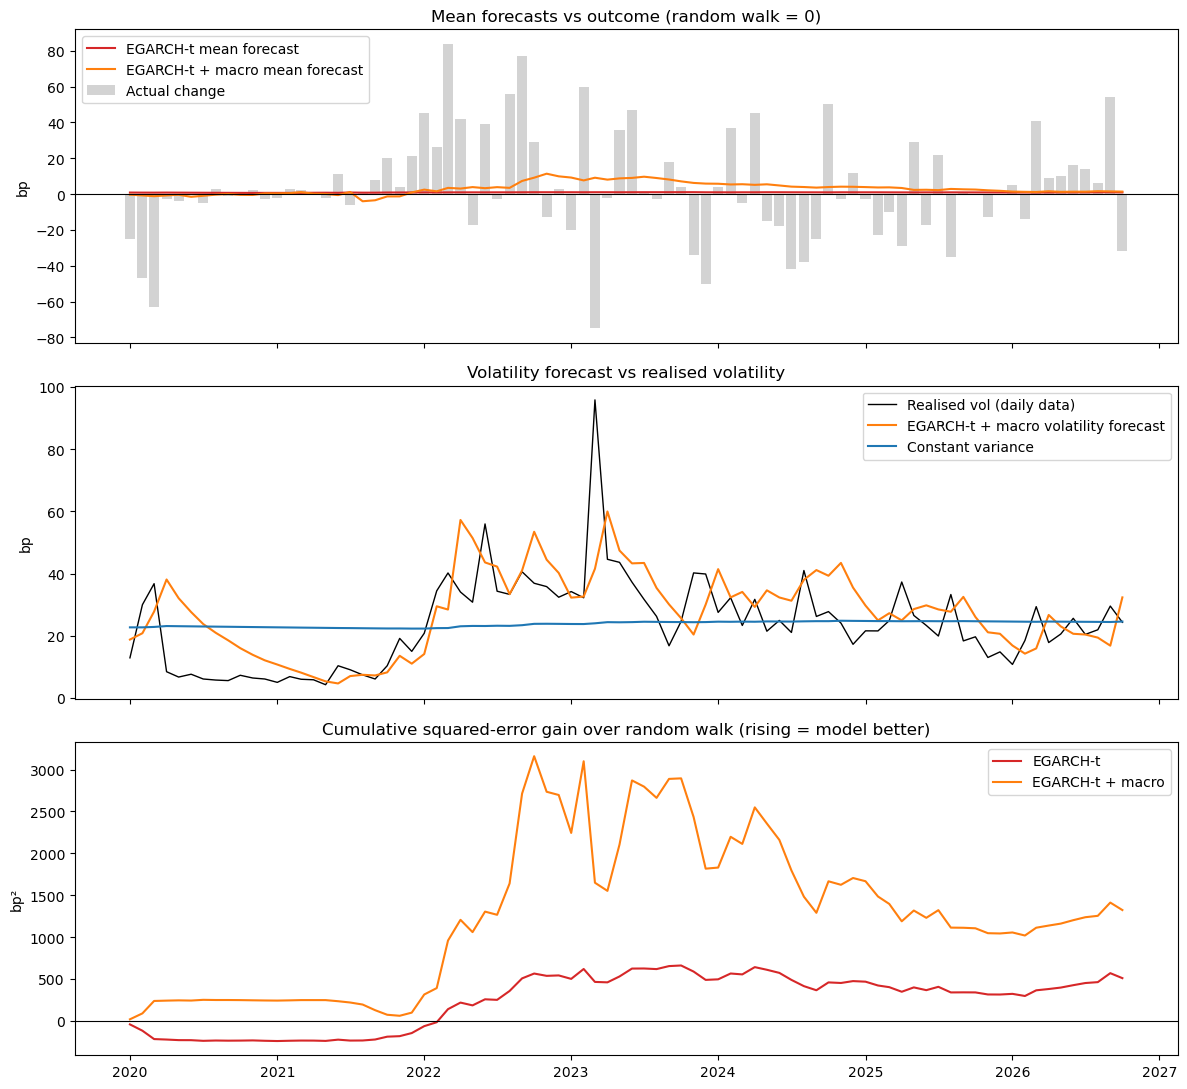

In [88]:
# Out-of-sample forecasts: EGARCH-t with (egx) and without (eg0) macro regressors

df     = df.squeeze()
df_oos = df_oos.squeeze()
X = pd.concat([macro_is, macro_oos]).ffill()    # same regressors as macro_is, over the full sample
k = X.shape[1]
fc = pd.DataFrame(index=df_oos.index, columns=["eg_mean", "eg_var", "eg_nu", "egx_mean", "egx_var", "egx_nu"], dtype=float)

for t in df_oos.index:  # Expanding window forecasts: re-estimate each month
    origin = df.index[df.index.get_loc(t) - 1]   # forecast is made the month before t
    y = df.loc[:origin]                          # data available at the origin

    # eg0: EGARCH-t without macro (benchmark)
    eg0_t = arch_model(y, mean="Constant", vol="EGARCH", p=1, q=1,dist="t", rescale=False).fit(disp="off", show_warning=False)
    f0 = eg0_t.forecast(horizon=1, reindex=False)

    # egx: EGARCH-t with macro regressors
    egx_t = arch_model(y, x=X.loc[y.index], mean="LS", vol="EGARCH", p=1, q=1,dist="t", rescale=False).fit(disp="off", show_warning=False)
    fx = egx_t.forecast(horizon=1, x=X.loc[t].to_numpy().reshape(k, 1, 1), reindex=False)  # month-t regressors (t-2 data)

    fc.loc[t] = [f0.mean.iloc[-1, 0], f0.variance.iloc[-1, 0], eg0_t.params["nu"],
                 fx.mean.iloc[-1, 0], fx.variance.iloc[-1, 0], egx_t.params["nu"]]

# Benchmarks for mean and variance:
actual    = df_oos
rw_mean   = pd.Series(0.0, index=actual.index)                   # random walk: no change
hist_mean = df.expanding().mean().shift(1).loc[actual.index]     # average of past changes
hist_var  = df.expanding().var().shift(1).loc[actual.index]      # constant variance: variance of past changes

# Realised variance from daily data: the "true" variance proxy for scoring volatility forecasts
dd = 100 * two_year_note.diff()
rv = (dd ** 2).groupby(dd.index.to_period("M")).sum()
rv.index = rv.index.to_timestamp()
rv = rv.loc[actual.index]

def hac_t(d):
    # t-stat for mean(d) = 0 with Newey–West standard errors
    d = np.asarray(d, dtype=float)
    r = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": int(len(d) ** (1 / 3))})
    return float(r.tvalues[0])

def clark_west_p(f_small, f_big):
    # One-sided: does the bigger (nesting) model beat the smaller one?
    e1, e2 = actual - f_small, actual - f_big
    return 1 - stats.norm.cdf(hac_t(e1**2 - (e2**2 - (f_small - f_big)**2)))

# Mean forecasts vs random walk
e_rw = actual - rw_mean
print("MEAN FORECASTS")
print(f"  Random walk          RMSE = {np.sqrt((e_rw**2).mean()):.1f}bp")
for name, f in [("Historical mean", hist_mean), ("EGARCH-t", fc["eg_mean"]), ("EGARCH-t + macro", fc["egx_mean"])]:
    e = actual - f
    ratio = np.sqrt((e**2).mean() / (e_rw**2).mean())
    r2 = 1 - (e**2).sum() / (e_rw**2).sum()
    print(f"  {name:20s} RMSE = {np.sqrt((e**2).mean()):.1f}bp   RMSE/RW = {ratio:.3f}   OOS R² = {r2:.1%}   CW p vs RW = {clark_west_p(rw_mean, f):.2f}")
print(f"  CW p (macro model vs EGARCH-t) = {clark_west_p(fc['eg_mean'], fc['egx_mean']):.2f}")

# Volatility forecasts vs constant variance
qlike = lambda h: np.log(h) + rv / h                             # lower = better
def coverage(m, v, nu):
    q90 = stats.t.ppf(0.95, nu) * np.sqrt((nu - 2) / nu) * np.sqrt(v)
    return ((actual - m).abs() <= q90).mean()

print("\nVOLATILITY FORECASTS (scored against realised variance from daily data)")
print(f"  Constant variance    QLIKE = {qlike(hist_var).mean():.3f}   avg σ = {np.sqrt(hist_var).mean():.1f}bp")
for name, p in [("EGARCH-t", "eg"), ("EGARCH-t + macro", "egx")]:
    v = fc[f"{p}_var"]
    dm_p = 2 * (1 - stats.norm.cdf(abs(hac_t(qlike(hist_var) - qlike(v)))))
    cov = coverage(fc[f"{p}_mean"], v, fc[f"{p}_nu"])
    print(f"  {name:20s} QLIKE = {qlike(v).mean():.3f}   avg σ = {np.sqrt(v).mean():.1f}bp   DM p vs constant = {dm_p:.3f}   90% coverage = {cov:.0%}")

# Plot
fig, ax = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
ax[0].bar(actual.index, actual.to_numpy(), width=25, color="lightgrey", label="Actual change")
ax[0].plot(fc.index, fc["eg_mean"].to_numpy(), color="tab:red", label="EGARCH-t mean forecast")
ax[0].plot(fc.index, fc["egx_mean"].to_numpy(), color="tab:orange", label="EGARCH-t + macro mean forecast")
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylabel("bp"); ax[0].legend()
ax[0].set_title("Mean forecasts vs outcome (random walk = 0)")
ax[1].plot(rv.index, np.sqrt(rv).to_numpy(), color="k", lw=1, label="Realised vol (daily data)")
ax[1].plot(fc.index, np.sqrt(fc["egx_var"]).to_numpy(), color="tab:orange", label="EGARCH-t + macro volatility forecast")
ax[1].plot(hist_var.index, np.sqrt(hist_var).to_numpy(), color="tab:blue", label="Constant variance")
ax[1].set_ylabel("bp"); ax[1].legend()
ax[1].set_title("Volatility forecast vs realised volatility")
for name, f, c in [("EGARCH-t", fc["eg_mean"], "tab:red"), ("EGARCH-t + macro", fc["egx_mean"], "tab:orange")]:
    ax[2].plot(actual.index, (e_rw**2 - (actual - f)**2).cumsum().to_numpy(), color=c, label=name)
ax[2].axhline(0, color="k", lw=0.8); ax[2].set_ylabel("bp²"); ax[2].legend()
ax[2].set_title("Cumulative squared-error gain over random walk (rising = model better)")
plt.tight_layout(); plt.show()

In [ ]:
# Conclusion: direction of yield changes not forecastable by its histroy or lagged macro variables. Size of yield
# changes ie volatility is forecastable with EGARCH predicting size of monthly move better than constant var benchmark